# Classification with Decision Trees

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

---

## Loading and Inspection of the data

This data set includes descriptions of hypothetical samples corresponding to 23 species of gilled mushrooms in the Agaricus and Lepiota Family (pp. 500-525).  Each species is identified as definitely edible, definitely poisonous, or of unknown edibility and not recommended.  This latter class was combined with the poisonous one.  The Guide clearly states that there is no simple rule for determining the edibility of a mushroom; no rule like ``leaflets three, let it be'' for Poisonous Oak and Ivy.

In [3]:
path_csv = "https://raw.githubusercontent.com/LorenzoTonet/Intro_to_ML_26-27/refs/heads/main/data/Mushroom.csv"
df = pd.read_csv(path_csv)
df.head()

,CLASS,CAP-SHAPE,CAP-SURF,CAP-COLOR,BRUISES,ODOR,GILL-ATTACH,GILL-SPACE,GILL-SIZE,GILL-COLOR,...,STALK-SURF-BELOW,STALK-COLOR-ABOVE,STALK-COLOR-BELOW,VEIL-TYPE,VEIL-COLOR,RING-NUM,RING-TYPE,SPORE-PRINT-COLOR,POP,HABIT
0,EDIBLE,CONVEX,SMOOTH,WHITE,BRUISES,ALMOND,FREE,CROWDED,NARROW,WHITE,...,SMOOTH,WHITE,WHITE,PARTIAL,WHITE,ONE,PENDANT,PURPLE,SEVERAL,WOODS
1,EDIBLE,CONVEX,SMOOTH,WHITE,BRUISES,ALMOND,FREE,CROWDED,NARROW,WHITE,...,SMOOTH,WHITE,WHITE,PARTIAL,WHITE,ONE,PENDANT,BROWN,SEVERAL,WOODS
2,EDIBLE,CONVEX,SMOOTH,WHITE,BRUISES,ALMOND,FREE,CROWDED,NARROW,PINK,...,SMOOTH,WHITE,WHITE,PARTIAL,WHITE,ONE,PENDANT,PURPLE,SEVERAL,WOODS
3,EDIBLE,CONVEX,SMOOTH,WHITE,BRUISES,ALMOND,FREE,CROWDED,NARROW,PINK,...,SMOOTH,WHITE,WHITE,PARTIAL,WHITE,ONE,PENDANT,BROWN,SEVERAL,WOODS
4,EDIBLE,CONVEX,SMOOTH,WHITE,BRUISES,ALMOND,FREE,CROWDED,NARROW,BROWN,...,SMOOTH,WHITE,WHITE,PARTIAL,WHITE,ONE,PENDANT,PURPLE,SEVERAL,WOODS


<Axes: xlabel='CLASS'>

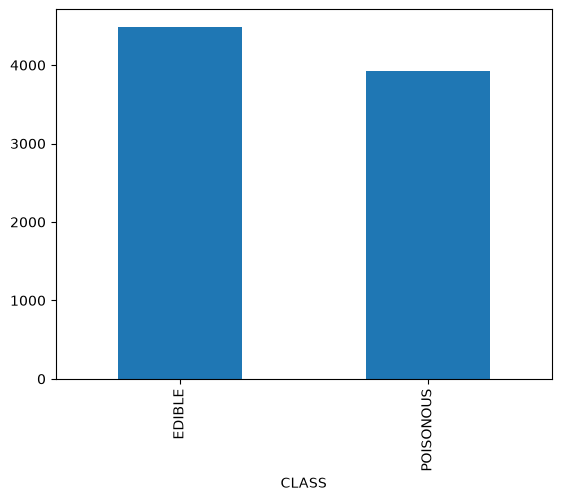

In [4]:
class_counts = df['CLASS'].value_counts()
class_counts.plot(kind='bar')

In [5]:
df.shape

(8416, 23)

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(df.drop("CLASS", axis=1), df["CLASS"], test_size=0.3, random_state=67)

## Decision Trees

**Using Decision Trees for Classification with ID3 (Iterative Dichotomiser 3)**

Here's a breakdown:

**Recall:**

- **Decision Building:**
  - We build a decision tree from a dataset.
  - Each node in the tree is like a checkpoint, helping us make a decision (internal node) or representing an outcome (leaves).

- **ID3 Algorithm:**
  - ID3 is a top-down approach (starting from the root) and a greedy algorithm (only considers the current step when choosing the best features) for building decision trees.

- **Feature Selection:**
  - At each step, features are grouped based on **information gain**.
  - Information gain helps us decide which feature is the most useful for making decisions.
  - **Entropy Formula:** $H(S) = \sum_{i=1}^D -p_i \log p_i$, where $p_i$ is the proportion of each category.
  - **Information Gain Formula:** $IG(S, j)=H(s) - \sum_j \frac{|S_j|}{|S|}H(S_j)$

- **Node Selection:**
  - A node becomes a leaf if all the data in that node belong to the same class.

- **Tree Construction:**
  - Repeat this process until the tree has only leaf nodes or until we've used all available features.

We start at the top and make decisions at each step based on the most helpful information. This continues until all our decisions (leaves) are clear or until we've used up all the information we have.

### Tips
* `.unique()` returns an iterator with all the values of the series (id3 split is based on branches for each category)
* `.nunique()` returns the number of unique values (usefull to check if a subgroup is "pure")

In [10]:
import numpy as np

class ID3DecisionTree:
    """
    The tree is a nested dictionary: {feature: {value: subtree_or_label}}
    """

    def __init__(self):
        self.tree = None

    # ---------- 1. Entropy and information gain ----------
    def entropy(self, y):
        """H(S) = - sum_c p_c * log2(p_c)"""
        h = 0
        for c in y.unique():
            p = (y == c).sum() / len(y)
            h = h - p * np.log2(p)
        return h

    def information_gain(self, X, y, feature):
        """IG = H(S) - sum_v |S_v|/|S| * H(S_v)"""
        weighted_entropy = 0

        for value in X[feature].unique():
            y_subset = y[X[feature] == value]

            weight = len(y_subset) / len(y)
            weighted_entropy += weight * self.entropy(y_subset)

        return self.entropy(y) - weighted_entropy

    def best_feature(self, X, y):
        """Feature with the highest information gain."""
        best_feature = None
        best_gain = -1

        for feature in X.columns:
            gain = self.information_gain(X, y, feature)

            if gain > best_gain:
                best_gain = gain
                best_feature = feature

        return best_feature

    # ---------- 2. Training ----------
    def build_tree(self, X, y):
        # Stop 1: all points have the same label -> leaf
        if y.nunique() == 1:
            return y.iloc[0]

        # Stop 2: no features left -> leaf with the most common label
        if len(X.columns) == 0:
            return y.mode()[0]

        # Otherwise: split on the best feature
        feature = self.best_feature(X, y)
        branches = {}

        for value in X[feature].unique():
            mask = X[feature] == value

            X_subset = X.loc[mask].drop(columns=[feature])
            y_subset = y.loc[mask]

            branches[value] = self.build_tree(X_subset, y_subset)

        return {feature: branches}

    def fit(self, X, y):
        self.default_class = y.mode()[0]
        self.tree = self.build_tree(X, y)
        return self

    # ---------- 3. Prediction ----------
    def predict_one(self, x, node):
        if not isinstance(node, dict):
            return node

        feature = list(node.keys())[0]
        branches = node[feature]
        value = x[feature]

        if value in branches:
            return self.predict_one(x, branches[value])

        return self.default_class

    def predict(self, X):
        predictions = []

        for i in range(len(X)):
            predictions.append(
                self.predict_one(X.iloc[i], self.tree)
            )

        return predictions

    def score(self, X, y):
        predictions = self.predict(X)
        correct = 0

        for i in range(len(y)):
            if predictions[i] == y.iloc[i]:
                correct += 1

        return correct / len(y)

    # ---------- 4. Printing ----------
    def print_tree(self, node=None, depth=0):
        if node is None:
            node = self.tree

        if not isinstance(node, dict):
            print("    " * depth + f"-> {node}")
            return

        feature = list(node.keys())[0]

        for value, child in node[feature].items():
            print("    " * depth + f"if {feature} = {value}:")

            if isinstance(child, dict):
                self.print_tree(child, depth + 1)
            else:
                print("    " * (depth + 1) + f"-> {child}")

In [11]:
tree = ID3DecisionTree()
tree.fit(X_train, y_train)

print("Decision tree:")
tree.print_tree()

Decision tree:
if ODOR = NONE:
    if SPORE-PRINT-COLOR = BROWN:
        -> EDIBLE
    if SPORE-PRINT-COLOR = WHITE:
        if HABIT = GRASSES:
            -> EDIBLE
        if HABIT = LEAVES:
            if CAP-COLOR = BROWN:
                -> EDIBLE
            if CAP-COLOR = CINNAMON:
                -> EDIBLE
            if CAP-COLOR = WHITE:
                -> POISONOUS
            if CAP-COLOR = YELLOW:
                -> POISONOUS
        if HABIT = WASTE:
            -> EDIBLE
        if HABIT = WOODS:
            if GILL-SIZE = NARROW:
                -> POISONOUS
            if GILL-SIZE = BROAD:
                -> EDIBLE
        if HABIT = PATHS:
            -> EDIBLE
    if SPORE-PRINT-COLOR = BLACK:
        -> EDIBLE
    if SPORE-PRINT-COLOR = GREEN:
        -> POISONOUS
    if SPORE-PRINT-COLOR = BUFF:
        -> EDIBLE
    if SPORE-PRINT-COLOR = YELLOW:
        -> EDIBLE
    if SPORE-PRINT-COLOR = ORANGE:
        -> EDIBLE
    if SPORE-PRINT-COLOR = CHOCOLATE:
        

In [12]:
y_pred = tree.predict(X_test)
print(f"Accuracy on test set: {tree.score(X_test, y_test):.2f}")

Accuracy on test set: 1.00


In [14]:
from sklearn.metrics import confusion_matrix

y_pred = tree.predict(X_test)

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

KeyError: 'ODOR'

---

### As always...

Take a look at the [official documentation](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html) to see all the different parameters

### Gini Index in Decision Trees

In classification problems, the Gini Index measures the probability of incorrectly classifying a randomly selected observation if its class label were assigned randomly according to the class distribution within the node.

The formula is:

$$
Gini = 1 - \sum_{i=1}^{K} p_i^2
$$

where:
- $K$ is the number of classes in the node;
- $p_i$ is the proportion of observations belonging to class $i$.

### Interpretation

- **Gini = 0**: the node is pure, meaning that all observations belong to the same class.
- **Higher Gini values**: the node contains observations belonging to different classes and is therefore more impure.
- **Maximum impurity**: occurs when all classes are equally represented. With $K$ classes, the maximum value is $1 - \frac{1}{K}$.

In [13]:
#Decision tree for by sklearn
from sklearn.tree import DecisionTreeClassifier

X = pd.get_dummies(df.drop(columns="CLASS"))
y = df["CLASS"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=67)

sk_tree = DecisionTreeClassifier(criterion='entropy', max_depth=100, min_samples_split=2, min_samples_leaf=1,)
sk_tree.fit(X_train, y_train)
print(sk_tree.score(X_test, y_test))

0.9988118811881188


---